In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    average_precision_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    cohen_kappa_score,
    ConfusionMatrixDisplay,
    roc_auc_score
)

In [32]:
train = pd.read_csv("landslide_train_engineered.csv")
test = pd.read_csv("landslide_test_engineered.csv")

In [33]:
print("Training shape:", train.shape)
print("Test shape:", test.shape)

Training shape: (9945, 48)
Test shape: (2464, 48)


In [34]:
print(train.head())

   Aspect_z  Dist_River_z  Elevation_z  FlowAccumulation_z    NDVI_z  \
0 -1.196783     -0.115485    -1.198316           -0.388618 -0.218111   
1 -1.055014     -0.127904    -1.198316           -0.578275 -0.783018   
2 -1.308173     -0.119583    -1.198316           -0.578275 -0.288624   
3  0.585456     -0.127251    -1.198316            0.422743 -0.399849   
4 -0.477812     -0.130197    -1.198316            2.962928 -0.164858   

   Rainfall_z   Slope_z  Dist_River_log  FlowAccumulation_log  Elevation_log  \
0   -1.344291 -1.694571        0.015821              0.173665       0.000000   
1   -1.344291 -1.768923        0.003521              0.000000       0.000791   
2   -1.344291 -1.917626        0.011779              0.000000       0.001582   
3   -0.498662 -1.471517        0.004172              0.693656       0.001582   
4   -1.063599 -1.768923        0.001234              1.513192       0.002371   

   ...  LULC_20  LULC_30  LULC_40  LULC_50  LULC_60  LULC_70  LULC_80  \
0  ...       

In [35]:
X_train = train.drop(columns=["class"])
y_train = train["class"]


In [36]:
X_test = test.drop(columns=["class"])
y_test = test["class"]


In [37]:
assert list(X_train.columns) == list(X_test.columns)

In [38]:
print("Number of input features:", X_train.shape[1])
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Number of input features: 47
Training samples: 9945
Testing samples: 2464


In [39]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)


In [40]:
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [41]:
print("Random Forest training completed!")

Random Forest training completed!


In [42]:
y_pred = rf_model.predict(X_test)

y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Predictions completed!")
print("First 10 predictions:", y_pred[:10])

Predictions completed!
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


In [43]:
tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

In [44]:
results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, zero_division=0
    ),
    "Recall / Sensitivity": recall_score(
        y_test, y_pred, zero_division=0
    ),
    "Specificity": tn / (tn + fp) if (tn + fp) else 0,
    "F1-score": f1_score(
        y_test, y_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
    "PR-AUC (Average Precision)": average_precision_score(
        y_test, y_prob
    ),
    "Balanced Accuracy": balanced_accuracy_score(
        y_test, y_pred
    ),
    "MCC": matthews_corrcoef(y_test, y_pred),
    "Cohen's Kappa": cohen_kappa_score(y_test, y_pred)
}


In [45]:
print("Random Forest — Evaluation Results")
print("-" * 42)
for metric, value in results.items():
    print(f"{metric}: {value:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Non-landslide", "Landslide"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))


Random Forest — Evaluation Results
------------------------------------------
Accuracy: 0.8068
Precision: 0.8047
Recall / Sensitivity: 0.8263
Specificity: 0.7861
F1-score: 0.8154
ROC-AUC: 0.8930
PR-AUC (Average Precision): 0.8895
Balanced Accuracy: 0.8062
MCC: 0.6131
Cohen's Kappa: 0.6129

Detailed Classification Report:
               precision    recall  f1-score   support

Non-landslide       0.81      0.79      0.80      1192
    Landslide       0.80      0.83      0.82      1272

     accuracy                           0.81      2464
    macro avg       0.81      0.81      0.81      2464
 weighted avg       0.81      0.81      0.81      2464

Confusion Matrix:
[[ 937  255]
 [ 221 1051]]


In [46]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-landslide", "Landslide"]
)


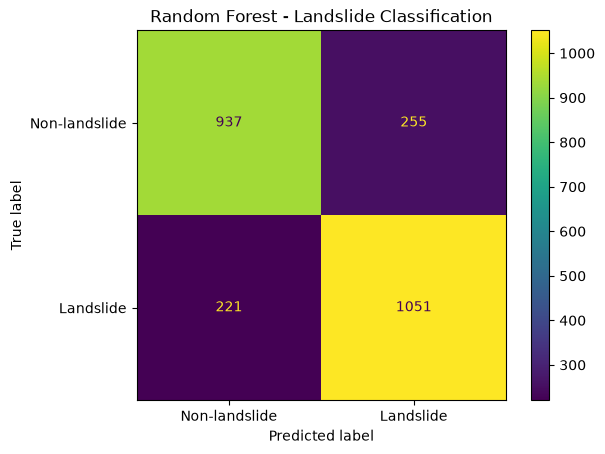

In [47]:
disp.plot()
plt.title("Random Forest - Landslide Classification")
plt.show()

In [48]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importance.head(15))

Hazard_index           0.080580
Elevation_sq           0.076248
Elevation_z            0.075374
Elevation_log          0.068171
Rainfall_minus_Elev    0.048546
Slope_minus_NDVI       0.047903
NDVI_z                 0.040934
Slope_z                0.039180
Rainfall_z             0.036504
Elevation_bin          0.036418
NDVI_sq                0.033774
Rainfall_x_NDVI        0.033605
Slope_sq               0.028415
Slope_x_NDVI           0.028333
Rainfall_sq            0.027876
dtype: float64


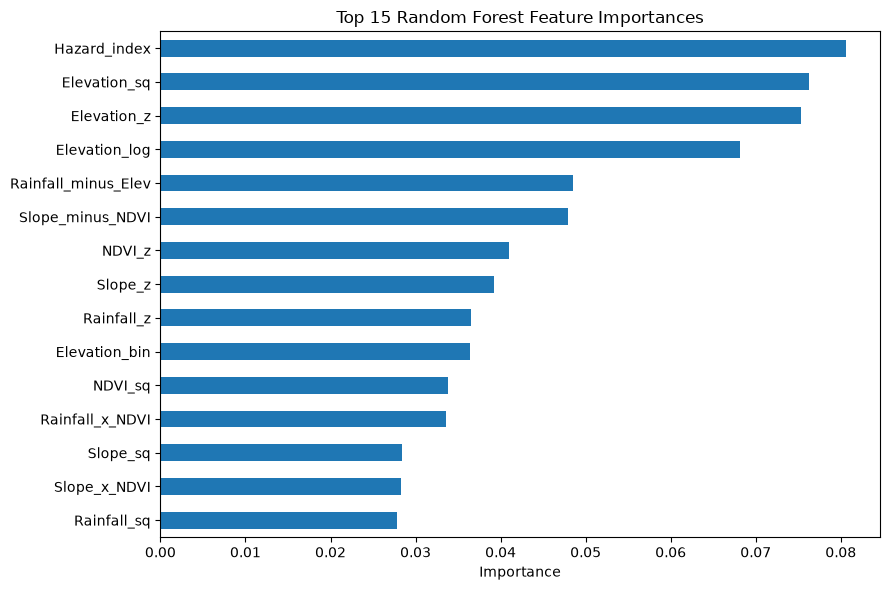

In [49]:
importance.head(15).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()